In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
tickers= ["NVDA", "AMD", "AVGO", "MU", "INTC", "^GSPC"]

start_date= "2020-06-01"
end_date= "2026-06-01"

prices= yf.download(tickers, start=start_date, end=end_date, auto_adjust=True, progress=False)
adjusted_prices=prices["Close"]
print(adjusted_prices.head())
print()
print(adjusted_prices.tail())
print()
print(adjusted_prices.isna().sum())

Ticker            AMD       AVGO       INTC         MU      NVDA        ^GSPC
Date                                                                         
2020-06-01  53.630001  25.233149  55.144672  45.187851  8.751850  3055.729980
2020-06-02  53.540001  25.935345  55.376446  45.655930  8.770736  3080.820068
2020-06-03  52.730000  26.933395  55.207069  47.703716  8.715329  3122.870117
2020-06-04  52.630001  26.877707  56.134174  49.946537  8.716324  3112.350098
2020-06-05  53.099998  27.590347  57.355446  52.384369  8.868947  3193.929932

Ticker             AMD        AVGO        INTC          MU        NVDA  \
Date                                                                     
2026-05-22  467.510010  412.734039  119.839996  750.884521  214.838928   
2026-05-26  503.890015  420.577301  123.519997  895.742249  214.370010   
2026-05-27  495.540009  420.427795  121.769997  928.267212  212.115158   
2026-05-28  518.090027  425.131775  120.889999  923.377991  213.761383   
2026-05-2

Downloads adjusted daily closing prices for NVIDIA, AMD, Broadcom, Micron, Intel, and S&P.  Note that the date range starts earlier than the expected window, so that the first monthly return can be correctly calculated.

In [3]:
monthly_prices= adjusted_prices.resample("ME").last()
monthly_returns=monthly_prices.pct_change().dropna()

print("\nMonthly prices: ")
print(monthly_prices.head())

print("\nMonthly returns: ")
print(monthly_returns.head())

print("\nNumber of Monthly Observations: ")
print(len(monthly_returns))


Monthly prices: 
Ticker            AMD       AVGO       INTC         MU       NVDA        ^GSPC
Date                                                                          
2020-06-30  52.610001  27.745367  53.335045  50.239067   9.443387  3100.290039
2020-07-31  77.430000  27.845583  42.548576  48.815376  10.553994  3271.120117
2020-08-31  90.820000  30.518063  45.727493  44.378487  13.297950  3500.310059
2020-09-30  81.989998  32.319477  46.472412  45.792439  13.457078  3363.000000
2020-10-31  75.290001  31.016287  39.741180  49.088409  12.465989  3269.959961

Monthly returns: 
Ticker           AMD      AVGO      INTC        MU      NVDA     ^GSPC
Date                                                                  
2020-07-31  0.471773  0.003612 -0.202240 -0.028338  0.117607  0.055101
2020-08-31  0.172930  0.095975  0.074713 -0.090891  0.259992  0.070065
2020-09-30 -0.097225  0.059028  0.016290  0.031861  0.011966 -0.039228
2020-10-31 -0.081717 -0.040322 -0.144844  0.071976 -0.0

The second line of code in this block is most important- it uses the calculation (Pt/Pt-1)-1 to calulcate returns in a percentage based value.

In [4]:
tickers_stock= ["NVDA", "AMD", "AVGO", "MU", "INTC"]

monthly_returns["Portfolio"]= monthly_returns[tickers_stock].mean(axis=1)
print("\nPortfolio returns: ")
print(monthly_returns[["Portfolio", "^GSPC"]].head())


Portfolio returns: 
Ticker      Portfolio     ^GSPC
Date                           
2020-07-31   0.072483  0.055101
2020-08-31   0.102544  0.070065
2020-09-30   0.004384 -0.039228
2020-10-31  -0.053711 -0.027666
2020-11-30   0.164301  0.107546


In [5]:
#Calculate the variance of each stock's returns in a month
stock_variance= monthly_returns[tickers_stock].var()
print(stock_variance)

Ticker
NVDA    0.019543
AMD     0.036925
AVGO    0.011982
MU      0.032658
INTC    0.034409
dtype: float64


Here, we are measuring how much each stock's monthly returns fluctuate.  For instance, the higher the variance, the more volatile the stock is. Here, AVGO and NVDA are around half as volatile as the other stocks in the portfolio. Now, we are going to give less weight to the stocks that fluctuated the most historically. 

In [6]:
#calculate inverse variances
stock_inverse_variance = 1 / stock_variance

inverse_weights= stock_inverse_variance/stock_inverse_variance.sum()

print("Inverse Variance Weights: ")
print(inverse_weights)


Inverse Variance Weights: 
Ticker
NVDA    0.231122
AMD     0.122325
AVGO    0.376975
MU      0.138308
INTC    0.131270
dtype: float64


Here, we assign each stock a weight of 20 percent, because equal portfolios are easy to explain when providing findings for clarity.  They are also easy to reproduce.

In [7]:
monthly_returns.to_csv("monthly_returns.csv")
print("\nData saved as monthly_returns.csv")


Data saved as monthly_returns.csv


This line saves the data taken into a csv file for comparison later on.

Now, we need 4 variables for the FAMA-French model
1) Market Risk Premium (Mkt-RF)
2) SMB (Small minus Big)
3) HML (High minus Low)
4) Risk-Free Rate (RF)

We will use the pandas_datareader package to download the Kenneth French dataset.

In [8]:
import pandas as pd

url= "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip"
ff_data= pd.read_csv(url, compression="zip", skiprows=3)
#Name first column as "Date" for clarity
ff_data= ff_data.rename(columns={ff_data.columns[0]: "Date"})
#Keep only monthly rows with dates containing six digits
ff_data["Date"]=ff_data["Date"].astype(str).str.strip()

ff_data=ff_data[ff_data["Date"].str.fullmatch(r"\d{6}", na=False)].copy()
#Convert the date into a month end timestamp
ff_data["Date"]= (
pd.to_datetime(ff_data["Date"], format= "%Y%m")
+pd.offsets.MonthEnd(0)
)
ff_data=ff_data.set_index("Date")
#Convert factor columns from text to numbers
factor_columns= ["Mkt-RF", "SMB", "HML", "RF"]
ff_data[factor_columns]=ff_data[factor_columns].apply(pd.to_numeric, errors="coerce")
#Convert factor columns to decimals
ff_data[factor_columns]= ff_data[factor_columns]/100
#Only keep period useful to this analysis in particular, the period of 2020-06-01 to 2026-06-01
ff_data= ff_data.loc["2020-07-31":]

print(ff_data.head())
print()
print(ff_data.tail())

            Mkt-RF     SMB     HML      RF
Date                                      
2020-07-31  0.0583 -0.0235 -0.0144  0.0001
2020-08-31  0.0762 -0.0020 -0.0302  0.0001
2020-09-30 -0.0364  0.0006 -0.0272  0.0001
2020-10-31 -0.0208  0.0434  0.0425  0.0001
2020-11-30  0.1245  0.0581  0.0209  0.0001

            Mkt-RF     SMB     HML      RF
Date                                      
2026-04-30  0.0995  0.0019 -0.0137  0.0029
2026-05-31  0.0491 -0.0159 -0.0231  0.0031
2026-06-30 -0.0107  0.0339  0.0358  0.0029
2026-07-31 -0.0061 -0.0192  0.0211  0.0033
2026-08-31  0.0256  0.0034 -0.0354  0.0029


In [9]:
model_data=monthly_returns.join(ff_data[["Mkt-RF", "SMB", "HML", "RF"]], how="inner")

print(model_data.head())
print()
print(model_data.tail())
print()
print("Number of matched months: ", len(model_data))

                 AMD      AVGO      INTC        MU      NVDA     ^GSPC  \
Date                                                                     
2020-07-31  0.471773  0.003612 -0.202240 -0.028338  0.117607  0.055101   
2020-08-31  0.172930  0.095975  0.074713 -0.090891  0.259992  0.070065   
2020-09-30 -0.097225  0.059028  0.016290  0.031861  0.011966 -0.039228   
2020-10-31 -0.081717 -0.040322 -0.144844  0.071976 -0.073648 -0.027666   
2020-11-30  0.230708  0.148586  0.099857  0.273142  0.069212  0.107546   

            Portfolio  Mkt-RF     SMB     HML      RF  
Date                                                   
2020-07-31   0.072483  0.0583 -0.0235 -0.0144  0.0001  
2020-08-31   0.102544  0.0762 -0.0020 -0.0302  0.0001  
2020-09-30   0.004384 -0.0364  0.0006 -0.0272  0.0001  
2020-10-31  -0.053711 -0.0208  0.0434  0.0425  0.0001  
2020-11-30   0.164301  0.1245  0.0581  0.0209  0.0001  

                 AMD      AVGO      INTC        MU      NVDA     ^GSPC  \
Date          

In [10]:
model_data["Portfolio-RF"]=(model_data["Portfolio"]-model_data["RF"])

print(model_data[["Portfolio", "RF", "Portfolio-RF", "Mkt-RF", "SMB", "HML"]].head())

            Portfolio      RF  Portfolio-RF  Mkt-RF     SMB     HML
Date                                                               
2020-07-31   0.072483  0.0001      0.072383  0.0583 -0.0235 -0.0144
2020-08-31   0.102544  0.0001      0.102444  0.0762 -0.0020 -0.0302
2020-09-30   0.004384  0.0001      0.004284 -0.0364  0.0006 -0.0272
2020-10-31  -0.053711  0.0001     -0.053811 -0.0208  0.0434  0.0425
2020-11-30   0.164301  0.0001      0.164201  0.1245  0.0581  0.0209


This calculates excess returns for the portfolio, not the raw return (essentially the total returns minus the monthly risk-free return is used to derive the excess return)

In [11]:
import statsmodels.api as sm

In [12]:
#Excess return
model_data["Portfolio_Excess"]= (model_data["Portfolio"]-model_data["RF"])

print(model_data[["Portfolio", "RF", "Portfolio_Excess", "Mkt-RF"]].head())

            Portfolio      RF  Portfolio_Excess  Mkt-RF
Date                                                   
2020-07-31   0.072483  0.0001          0.072383  0.0583
2020-08-31   0.102544  0.0001          0.102444  0.0762
2020-09-30   0.004384  0.0001          0.004284 -0.0364
2020-10-31  -0.053711  0.0001         -0.053811 -0.0208
2020-11-30   0.164301  0.0001          0.164201  0.1245


In [13]:
Y= model_data["Portfolio_Excess"]
X=model_data["Mkt-RF"]

X=sm.add_constant(X)

add_constant function generates the intercept (beta)

In [14]:
capm_model= sm.OLS(Y, X).fit()

print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:       Portfolio_Excess   R-squared:                       0.494
Model:                            OLS   Adj. R-squared:                  0.487
Method:                 Least Squares   F-statistic:                     67.37
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           8.32e-12
Time:                        14:28:39   Log-Likelihood:                 73.165
No. Observations:                  71   AIC:                            -142.3
Df Residuals:                      69   BIC:                            -137.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0208      0.011      1.940      0.0

Note the results- the "const" which is Alpha- whether the portfolio earned returns above what is expected by the CAPM. If the alpha is positive, it outperformed the CAPM. If negative, it underperformed the CAPM.  Additionally, beta- which is the market sensitivity- anything above 1 means it is more volatile than the market, and anything less means it is less volatile than the market. The R2 tells us how much of the portfolio's returns is explained by the CAPM.  The p-value for Mkt-RF tells us if the relationship is statistically significant (p-val <0.05= rejected the hypothesis)

To conclude, the alpha was positive- 0.0208.  In other words, the AI/semiconductor portfolio earned about 2.08% more per month than predicted by the CAPM. However, the p-value was 0.056, more than 0.05- which is slightly above the significance level of 0.05. This suggests outperformance relative to the CAPM, but the result was not statistically significant at the p-value of 0.05 (5% level).

The beta was 1.8352, which means it was more volatile than the market. This means that for every 1 % increase in the market's excess returns, the portfolio increased by about 1.84%.  Thus, the AI/semiconductor portfolio is much more sensitive to market movements than the overall market. This is worth noting.

The R2 was 0.494, which means about half of the data can be explained by the CAPM (49.4% of the variations in the portfolio's excess returns is explained by the market alone). The other 50.6% is due to other influences. 

The p-val was 0.000 for the Mkt-RF, which means it was less than 0.05, so the relationship is statistically significant. Thus, there is very strong statistical evidence that the market factor influences my portfolio's returns.

In [15]:
start= model_data["Portfolio-RF"]

end= model_data[["Mkt-RF"]]
start=sm.add_constant(start)

capm_model= sm.OLS(end, start).fit()

print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Mkt-RF   R-squared:                       0.494
Model:                            OLS   Adj. R-squared:                  0.487
Method:                 Least Squares   F-statistic:                     67.37
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           8.32e-12
Time:                        14:28:39   Log-Likelihood:                 141.31
No. Observations:                  71   AIC:                            -278.6
Df Residuals:                      69   BIC:                            -274.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0005      0.004      0.128   

Generates full regression table using CAPM

Step 2- Fama French 3-Factor Model.  This answers the main research question- adding 2 other variables (small minus big, high minus low)

In [16]:
Y= model_data["Portfolio_Excess"]

X=model_data[["Mkt-RF", "SMB", "HML"]]
X=sm.add_constant(X)

ff_model=sm.OLS(Y, X).fit()

print(ff_model.summary())

                            OLS Regression Results                            
Dep. Variable:       Portfolio_Excess   R-squared:                       0.524
Model:                            OLS   Adj. R-squared:                  0.503
Method:                 Least Squares   F-statistic:                     24.63
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           7.43e-11
Time:                        14:28:39   Log-Likelihood:                 75.367
No. Observations:                  71   AIC:                            -142.7
Df Residuals:                      67   BIC:                            -133.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0241      0.011      2.205      0.0

The R^2 value was 0.523, which means about 52.3% of the data can be explained by the FAMA French model.  This is worth noting, as about 49% of the data was explained by the CAPM model in comparison.

The alpha (const) was 0.0239, which means the AI/semiconductor portfolios earned about 2.39% more per month than predicted by the FAMA French 3 model. In addition, the p-value was 0.033, which supports our claim by showing that this was statistically significant (p-value<0.05).  The adjusted R^2 was 0.502, which is still higher than that of the CAPM.

The beta- the Market (Mkt-RF) was 1.7945, with a p-value of 0.000.  This means our data is statistically significant with a p-value below 0.05, and it was more volatile than the market. This means that for every 1 % increase in the market's excess returns, the portfolio increased by about 1.7945%. 

The SMB was -0.2382, but it is not statistically significant, as the p-value was 0.514.

The HML was -0.4783, however it is not statistically significant at the 5% level (p-value of 0.072)

To conclude thus far, the market risk can be explained by much of my portfolio. (R^2= 0.494).  According to the FAMA French Model, adding size and value to the equation improves the fit slightly (r^2=0.523), but the improvement is still modest. Market movements continued to be the dominant driver of returns, while the size and value factors contributed very little.

NOW, as we discussed, I decided to create an equal weight portfolio, an inverse-variance weight portfolio, and then compare the 2 amongst each other and note any differences.

In [17]:
#--------------------------------
#Equal weight portfolio vs. Inverse-variance weight
#--------------------------------


import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

#---------------------------------
#1. Select only the 5 stocks in my portfolio for comparison
#-------------------------------

stocks= ["AMD", "AVGO", "INTC", "MU", "NVDA"]

stock_returns= monthly_returns[stocks].copy()

print("Stocks included in the portfolio: ")
print(stocks)

#---------------------------------
#2. Original Equal weight portfolio
#---------------------------------

n_assets= len(stocks)

equal_weights= np.repeat(1/n_assets, n_assets)

equal_weight_portfolio= stock_returns.dot(equal_weights)

print("\nEqual weight portfolio returns: " )

for stock, weight in zip(stocks, equal_weights):
    print(f"{stock}: {weight:.2%}")

Stocks included in the portfolio: 
['AMD', 'AVGO', 'INTC', 'MU', 'NVDA']

Equal weight portfolio returns: 
AMD: 20.00%
AVGO: 20.00%
INTC: 20.00%
MU: 20.00%
NVDA: 20.00%


In [18]:
#---------------------------------
#3. Calculate variance of each indvidual stock
#---------------------------------

stock_variances= stock_returns.var()

print("\nIndividual stock variances: ")

print(stock_variances)



Individual stock variances: 
Ticker
AMD     0.036925
AVGO    0.011982
INTC    0.034409
MU      0.032658
NVDA    0.019543
dtype: float64


In [ ]:
#---------------------------------
#4. Calclate the inverse-variance weights
#Lower variance= higher portfolio weight
#WHY? Because the inverse of variance is a measure of how much risk an asset carries. 
#A lower variance indicates that the asset is less risky, and therefore, it should have a higher weight 
#in the portfolio to minimize overall risk. Conversely, a higher variance indicates more risk, 
#so it should have a lower weight in the portfolio. In this context, I am acting with risk-averse behavior,
# as I am trying to minimize the overall risk of the portfolio by allocating more weight to less risky assets.
#---------------------------------

inverse_variance= 1/stock_variances

variance_weights= inverse_variance/ inverse_variance.sum()

print("\nInverse-variance weights: ")

for stock, weight in variance_weights.items():
    print(f"{stock}: {weight:.2%}")

print("\nCheck that weights sum to: ")
print(f"{variance_weights.sum():.2%}")



Inverse-variance weights: 
AMD: 12.23%
AVGO: 37.70%
INTC: 13.13%
MU: 13.83%
NVDA: 23.11%

Check that weights sum to: 
100.00%


In [20]:
#---------------------------------
#5.Compare portfolio weights
#---------------------------------

weight_compare= pd.DataFrame({"Equal Weight": equal_weights, "Inverse-Variance Weight": variance_weights.values}, index=stocks)

print("\nWeight Comparison:")
print(weight_compare)


Weight Comparison:
      Equal Weight  Inverse-Variance Weight
AMD            0.2                 0.122325
AVGO           0.2                 0.376975
INTC           0.2                 0.131270
MU             0.2                 0.138308
NVDA           0.2                 0.231122


In [21]:
#---------------------------------
#To make it easier to read with percentages:
#---------------------------------

print("\nWeight Comparison (as percentages):")

print((weight_compare*100).round(2))



Weight Comparison (as percentages):
      Equal Weight  Inverse-Variance Weight
AMD           20.0                    12.23
AVGO          20.0                    37.70
INTC          20.0                    13.13
MU            20.0                    13.83
NVDA          20.0                    23.11


In [22]:
#Create inverse-variance weighted portfolio returns
variance_weighted_portfolio= stock_returns.dot(variance_weights)

#Add both portfolios to monthly returns
monthly_returns["Equal Weight Portfolio"]= equal_weight_portfolio 
monthly_returns["Variance-Weighted Portfolio"]= variance_weighted_portfolio

print(monthly_returns[["Equal Weight Portfolio", "Variance-Weighted Portfolio"]].head())



Ticker      Equal Weight Portfolio  Variance-Weighted Portfolio
Date                                                           
2020-07-31                0.072483                     0.055785
2020-08-31                0.102544                     0.114660
2020-09-30                0.004384                     0.019670
2020-10-31               -0.053711                    -0.051277
2020-11-30                0.164301                     0.151117


HERE, we changed how much of each stock is invested in the portfolio, with mitigating risk in mind. In comparison, AVGO has nearly 38% invested instead of 20%, while AMD, INTC, and MU have been reduced. Now, we need to compare the mean returns of the 2 portfolios for a measurable comparison.

In [23]:
portfolio_comparison= pd.DataFrame({
    "Mean Monthly Return": [
        equal_weight_portfolio.mean(), 
        variance_weighted_portfolio.mean()
    ],
    "Monthly Variance": [
        equal_weight_portfolio.var(),
        variance_weighted_portfolio.var()
    ],
    "Monthly Volatility": [
        equal_weight_portfolio.std(),
        variance_weighted_portfolio.std()
    ]
}, index=["Equal Weight Portfolio", "Variance-Weighted Portfolio"])

print(portfolio_comparison)

                             Mean Monthly Return  Monthly Variance  \
Equal Weight Portfolio                  0.045563            0.0150   
Variance-Weighted Portfolio             0.046387            0.0119   

                             Monthly Volatility  
Equal Weight Portfolio                 0.122476  
Variance-Weighted Portfolio            0.109088  


HERE, this shows that the variance-weighed portfolio produced a slightly higher average monthly return while taking less risk. This is notable, because this was something we wanted to investigate further. Volatality went from 12.25% to 10.91%, about an 11% reduction in monthly volatality relative to that of the equal-weight portfolio. Variance went from 0.0150 to 0.0119, which is roughly a 21% reduction in variance. The average mothly return went from 4.56% to 4.64%- this isn't much, but still worth noting. Using an inverse-variance method shifted the portfolio intentionally towards stocks that showed lower indivdual variance during the sample. 

NEW idea: Changing from equal weigthing to inverse-variance weighting substantially reduced portfolio risk without reducing the portfolio's average return. One note: these weights were calculated using the same historical period we evaluated, so they don't necessarily prove the variance weighted portfolio would continue to outperform in the future.

NEW idea: I have also opted to use the covariance matrix by producing a minumum variance portfolio in addition to the equal weight portfolio and inverse variance portfolio.  This is because the inverse variance portfolio tells us how volatile each stock is to market movements.  In changing the baseline portfolio weights, we can establish meaningful solutions.  However, minimum variance tells us not only how volatile the stocks are, but further how they move in relation to each other. For instance, two of these stocks may both be volatile, but they may not both move together in unison.  In short, we will be finding the lowest volatality combination of stocks without short selling. 

In [24]:
covariance= monthly_returns[tickers_stock].cov()

print("Covariance Matrix")
print(covariance)

Covariance Matrix
Ticker      NVDA       AMD      AVGO        MU      INTC
Ticker                                                  
NVDA    0.019543  0.016354  0.007362  0.007709  0.005944
AMD     0.016354  0.036925  0.010147  0.019885  0.017945
AVGO    0.007362  0.010147  0.011982  0.006105  0.007550
MU      0.007709  0.019885  0.006105  0.032658  0.020745
INTC    0.005944  0.017945  0.007550  0.020745  0.034409


The diagonal on the matrix is the variances we already have determined. The other values are the covariances- these tell us how two stocks move together. With a positive covariance, the two stocks tend to move together, while a negative covariance means they tend to move apart- specifically in opposite directions. Additionally, a covariance near zero tends to mean there is relatively little relationship. The main difference is that minimum variance determines the combination of stock weights with lowest possible portfolio variance considering two things- 1) their individual risk and 2) their relations with each other. 

Now, we are going to use scipy optimize- this performs mathematical and root-finding tasks within python code. 

In [25]:
from scipy.optimize import minimize
import numpy as np

#calculates portfolio variance 
def portfolio_variance(weights):
    return weights.T @ covariance.values @weights

#begin with equal weights 
beginning_weights= np.array([0.2, 0.2, 0.2, 0.2, 0.2])

#all weights add to 1
#eq means equal to 0, meaning sum(weights)-1=0, or sum(weights) must equate to 1
constraints= {"type": "eq", "fun": lambda weights: np.sum(weights)-1 }

#all weights in range from 1 to 100%
bounds= [(0, 1)]*len(tickers_stock)

#find the weights producing the lowest variance
#this tells us to minimize the portfolio, starting at beginning weight, 
#using the SLSQP algorithm, and obeying our bounds and constraints
result= minimize(portfolio_variance, beginning_weights,
                 method= "SLSQP", bounds=bounds, constraints=constraints)

min_variance_weight= result.x

for ticker, weight in zip(tickers_stock, min_variance_weight):
    print(f"{ticker}: {weight:.2%}")


NVDA: 22.59%
AMD: 0.00%
AVGO: 61.58%
MU: 9.59%
INTC: 6.24%


Now, we create the actual minimum variance portfolio and compare it to the equal weighted and inverse variance portfolios.

In [26]:
monthly_returns["Minimum Variance Portfolio"]= (monthly_returns[tickers_stock] @ min_variance_weight)

print(monthly_returns[["Equal Weight Portfolio", "Variance-Weighted Portfolio", "Minimum Variance Portfolio"]].head())


Ticker      Equal Weight Portfolio  Variance-Weighted Portfolio  \
Date                                                              
2020-07-31                0.072483                     0.055785   
2020-08-31                0.102544                     0.114660   
2020-09-30                0.004384                     0.019670   
2020-10-31               -0.053711                    -0.051277   
2020-11-30                0.164301                     0.151117   

Ticker      Minimum Variance Portfolio  
Date                                    
2020-07-31                    0.013448  
2020-08-31                    0.113775  
2020-09-30                    0.043124  
2020-10-31                   -0.043604  
2020-11-30                    0.139560  


This creates return series for each portfolio, multiplying the month's returns for all 5 stocks by their minimum variance weights just determined. Next, we will compare their volatality.

In [27]:
portfolio_volatility= monthly_returns[["Equal Weight Portfolio", "Variance-Weighted Portfolio", "Minimum Variance Portfolio"]].std()

print("Monthly Porfolio Volatality: ")
print(portfolio_volatility)

Monthly Porfolio Volatality: 
Ticker
Equal Weight Portfolio         0.122476
Variance-Weighted Portfolio    0.109088
Minimum Variance Portfolio     0.100373
dtype: float64


As expected, the minimum variance portfolio had the lowest volatality. It was specifically optimized to minimize variance. Now, we will compare the average returns of the portfolios.

In [28]:
average_returns= monthly_returns[["Equal Weight Portfolio", "Variance-Weighted Portfolio", "Minimum Variance Portfolio"]].mean()

print("Average Monthly Returns: ")
print(average_returns)

Average Monthly Returns: 
Ticker
Equal Weight Portfolio         0.045563
Variance-Weighted Portfolio    0.046387
Minimum Variance Portfolio     0.046955
dtype: float64


Here, we can see that the minimum variance portfolio also consequently had the highest average returns as well. However, this isn't to say that the minimum variance portfolio caused higher returns, because it didn't. My optimization only minimized variance, and the higher returns resulted from the portfolio weights chosen. 

Now, we want to ask how much excess return each portfolio generated compared to the amount of risk taken. This is where the Sharpe ratio comes into play.

In [29]:
#Align the risk free rate with the portfolio dates
#Calculates the excess returns for each portfolio- doing so by subtracting the risk free 
#rate from the monthly returns of each portfolio. This is important because the Sharpe 
#ratio measures the excess return per unit of risk, and the risk-free rate represents the
#return that an investor could earn without taking on any risk. By subtracting the risk-free
#rate from the portfolio returns, we can isolate the portion of the returns that is attributable
#to taking on risk, which is what we want to measure with the Sharpe ratio.

rf= ff_data["RF"].reindex(monthly_returns.index)
#defines the portfolios to be analyzed
portfolios= ["Equal Weight Portfolio", "Variance-Weighted Portfolio", "Minimum Variance Portfolio"]

#Determine monthly excess returns
excess_returns= monthly_returns[portfolios].subtract(rf, axis=0)

#Calculate annualized Sharpe ratio
sharpe_ratios= (excess_returns.mean()/excess_returns.std())*np.sqrt(12)

print("Annualized Sharpe Ratio")
print(sharpe_ratios)

Annualized Sharpe Ratio
Ticker
Equal Weight Portfolio         1.222983
Variance-Weighted Portfolio    1.400014
Minimum Variance Portfolio     1.542032
dtype: float64


The higher the Sharpe Ratio, the more excess return the portfolio historically generates per unit of volatality. We would expect the minimum variance portfolio to have the highest sharpe ratio because it not only had the lowest volatality at 10.037%, but also the highest returns monthly at 4.696%. In this case, it did have the highest Sharpe ratio- at 1.542. We are now going to run the CAPM and FAMA French on all 3 portfolios. 

In [30]:
regression_data= monthly_returns[["Equal Weight Portfolio", "Variance-Weighted Portfolio", "Minimum Variance Portfolio"]].join(ff_data[["Mkt-RF", "SMB", "HML", "RF"]], how="inner")
#.join matches everything to the date index
print(regression_data.head())

            Equal Weight Portfolio  Variance-Weighted Portfolio  \
Date                                                              
2020-07-31                0.072483                     0.055785   
2020-08-31                0.102544                     0.114660   
2020-09-30                0.004384                     0.019670   
2020-10-31               -0.053711                    -0.051277   
2020-11-30                0.164301                     0.151117   

            Minimum Variance Portfolio  Mkt-RF     SMB     HML      RF  
Date                                                                    
2020-07-31                    0.013448  0.0583 -0.0235 -0.0144  0.0001  
2020-08-31                    0.113775  0.0762 -0.0020 -0.0302  0.0001  
2020-09-30                    0.043124 -0.0364  0.0006 -0.0272  0.0001  
2020-10-31                   -0.043604 -0.0208  0.0434  0.0425  0.0001  
2020-11-30                    0.139560  0.1245  0.0581  0.0209  0.0001  


In [31]:
for portfolio in portfolios:
    regression_data[portfolio+ " Excess"]=(
regression_data[portfolio]-regression_data["RF"]
    )


In [32]:
import statsmodels.api as sm

capm_results= {}
for portfolio in portfolios:
    Y= regression_data[portfolio+ " Excess"]
    X= regression_data["Mkt-RF"]
    X= sm.add_constant(X)
    model= sm.OLS(Y, X).fit()
    capm_results[portfolio]= model

In [33]:
print("CAPM Results:\n")

for portfolio, model in capm_results.items():
    print(portfolio)
    print("Alpha: ", round(model.params["const"], 4))
    print("Beta: ", round(model.params["Mkt-RF"], 4))
    print("R-squared: ", round(model.rsquared, 4))
    print()

CAPM Results:

Equal Weight Portfolio
Alpha:  0.0208
Beta:  1.8353
R-squared:  0.494

Variance-Weighted Portfolio
Alpha:  0.0234
Beta:  1.6893
R-squared:  0.5282

Minimum Variance Portfolio
Alpha:  0.0266
Beta:  1.4759
R-squared:  0.4767



Changing ALPHA: represents changes to excess return
Changing BETA: represents changes to sensitivity in overall market
Changing R^2: represents how much of the variation in portfolios excess returns is explained by the model

In [34]:
ff3_results={}

for portfolio in portfolios:
    Y= regression_data[portfolio+ " Excess"]
    X= regression_data[["Mkt-RF", "SMB", "HML"]]
    X=sm.add_constant(X)
    model= sm.OLS(Y, X).fit()
    ff3_results[portfolio]=model

In this next section, I just wanted to work with computing daily returns of a stock that I used in my portfolio, and practicing visualization and plotting techniques. 

In [35]:
print("Fama French 3-Factor Results: \n")
for portfolio, model in ff3_results.items():
    print(portfolio)
    print("Alpha: ", round(model.params["const"], 4))
    print("Beta: ", round(model.params["Mkt-RF"], 4))
    print("SMB: ", round(model.params["SMB"], 4))
    print("HML: ", round(model.params["HML"], 4))
    print("R-squared: ", round(model.rsquared, 4))
    print()

Fama French 3-Factor Results: 

Equal Weight Portfolio
Alpha:  0.0241
Beta:  1.7867
SMB:  -0.2143
HML:  -0.4991
R-squared:  0.5245

Variance-Weighted Portfolio
Alpha:  0.0276
Beta:  1.6193
SMB:  -0.1912
HML:  -0.6066
R-squared:  0.5819

Minimum Variance Portfolio
Alpha:  0.0315
Beta:  1.3872
SMB:  -0.125
HML:  -0.6561
R-squared:  0.5476



This is notable, because as a result, the r^2 values increaseds significantly among all portfolios, wiht the variance-weighted portfolio still accounting for the largest r^2 value. What is most notable is that the FAMA-French increases r^2 across all 3 portfolios, indicating greater explanatory power than CAPM alone. Another interesting result is the SMB and HML values- they are all negative. This suggests that the portfolio behaved like growth-oriented stocks rather than value stocks. This makes sense relative to an AI/semiconductor portfolio.

In [36]:
print("Fama French Factor p-value results: \n")
for portfolio, model in ff3_results.items():
    print(portfolio)
    print("Alpha p-value: ", round(model.pvalues["const"], 4))
    print("Beta p-value: ", round(model.pvalues["Mkt-RF"], 4))
    print("SMB p-value: ", round(model.pvalues["SMB"], 4))
    print("HML p-value: ", round(model.pvalues["HML"], 4))
    print()

Fama French Factor p-value results: 

Equal Weight Portfolio
Alpha p-value:  0.0309
Beta p-value:  0.0
SMB p-value:  0.557
HML p-value:  0.06

Variance-Weighted Portfolio
Alpha p-value:  0.0034
Beta p-value:  0.0
SMB p-value:  0.5303
HML p-value:  0.0069

Minimum Variance Portfolio
Alpha p-value:  0.0006
Beta p-value:  0.0
SMB p-value:  0.6676
HML p-value:  0.0024



Given these data values from the FAMA Factor p-value results, the main distinction is that market exposure is signficant across all markets, but the relevance of the value factor is dependent on how we weigh the stocks. Overall, given the research question: "Does adding size and value factors explain this AI/semiconductor portfolio better than market risk alone? Given a 5% signficance level, these results provide that HML contributes useful explanatory information regarding the variance-weighted and minimum variance portfolios. This suggests that portfolio weighting affects exposure to the value factor and that adding HML may help explain returns beyond market exposure alone. The SMB (size factor) does not show a significant contribution. Significant alpha remained in all three portfolios, indicating that the three factors did not fully account for average excess returns.

Combined with the alpha values above, All three alphas are positive and statistically significant, indicating average excess returns above what the three-factor model explains during your sample. In regard to market exposure, betas range from 1.39 to 1.79, meaning all three portfolios have greater estimated sensitivity to market movements than a beta-1 portfolio. In regard to growth exposure, all HML coefficients are negative. This exposure is statistically significant for the variance-weighted and minimum-variance portfolios. exposure. SMB coefficients are negative, suggesting a large-cap direction, but your p-values do not establish significant size exposure. Fama–French explains approximately 52.45%, 58.19%, and 54.76% of the variation in excess returns, respectively. Thus, with the r2 in mind, the variance weighted portfolio has the highest Fama French R2, meaning the model fits its returns best among these three; it does not establish that this portfolio performs best.

One notable distinction is that the variance weighted portfolio has the highest Fama French R2, meaning the model fits its returns best among these three; it does not establish that this portfolio performs best. In order to find out which model performs best, we could use a Sharpe Ratio to compare the portfolios’ actual returns and risk over the same dates. \(R^2\) measures how well the regression explains returns—not how good those returns are. We can calclate annualized return, annualized volatality, a sharpe ratio, and maximum drawdown.

In [37]:
import yfinance as yf

nvidiadata= yf.download("NVDA", start= "2020-01-01", end ="2025-12-31")

nvidiadata.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA
Date,,,,,
2020-01-02,5.957138,5.957138,5.877928,5.928334,237536000
2020-01-03,5.861788,5.905490,5.812872,5.837702,205384000
2020-01-06,5.886372,5.891586,5.742602,5.768674,262636000
2020-01-07,5.957635,6.003324,5.869735,5.914678,314856000
2020-01-08,5.968808,6.010027,5.913436,5.953413,277108000


This displays the first 5 rows of NVIDIA historical stock data beginning in January of 2020.

In [38]:
nvidiadata["Daily Return"]= nvidiadata["Close"].pct_change()
nvidiadata.head()

Price,Close,High,Low,Open,Volume,Daily Return
Ticker,NVDA,NVDA,NVDA,NVDA,NVDA,
Date,,,,,,
2020-01-02,5.957138,5.957138,5.877928,5.928334,237536000,NaN
2020-01-03,5.861788,5.905490,5.812872,5.837702,205384000,-0.016006
2020-01-06,5.886372,5.891586,5.742602,5.768674,262636000,0.004194
2020-01-07,5.957635,6.003324,5.869735,5.914678,314856000,0.012107
2020-01-08,5.968808,6.010027,5.913436,5.953413,277108000,0.001875


Computes daily returns for NVIDIA stock

In [39]:
nvidiadata["Daily Return"].describe()

count    1506.000000
mean        0.002849
std         0.033514
min        -0.184521
25%        -0.015617
50%         0.003200
75%         0.021796
max         0.243696
Name: Daily Return, dtype: float64

In 1506 trading days, the average daily return was 0.28 percent, the standard deviation was 3.35 percent, with a maximum daily return of 24.36 percent, and a minumum daily return of 18.45 percent.

S&P 500 Benchmark

In [40]:
import yfinance as yf

sp500= yf.download("^GSPC", start= "2020-01-01", end ="2025-12-31")

sp500.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000


This downloads the S&P 500 index.

In [41]:
sp500["Daily Return"]= sp500["Close"].pct_change()
sp500.head()

Price,Close,High,Low,Open,Volume,Daily Return
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,
2020-01-02,3257.850098,3258.139893,3235.530029,3244.669922,3459930000,NaN
2020-01-03,3234.850098,3246.149902,3222.340088,3226.360107,3484700000,-0.007060
2020-01-06,3246.280029,3246.840088,3214.639893,3217.550049,3702460000,0.003533
2020-01-07,3237.179932,3244.909912,3232.429932,3241.860107,3435910000,-0.002803
2020-01-08,3253.050049,3267.070068,3236.669922,3238.590088,3726840000,0.004902


This calculates the percent change in each row of S&P data- the daily return. This allows all stocks to be put on the same scale, comparing performance across stocks and calculating volatality.

In [42]:
sp500["Daily Return"].describe()

count    1506.000000
mean        0.000585
std         0.013186
min        -0.119841
25%        -0.004810
50%         0.000975
75%         0.006875
max         0.095154
Name: Daily Return, dtype: float64

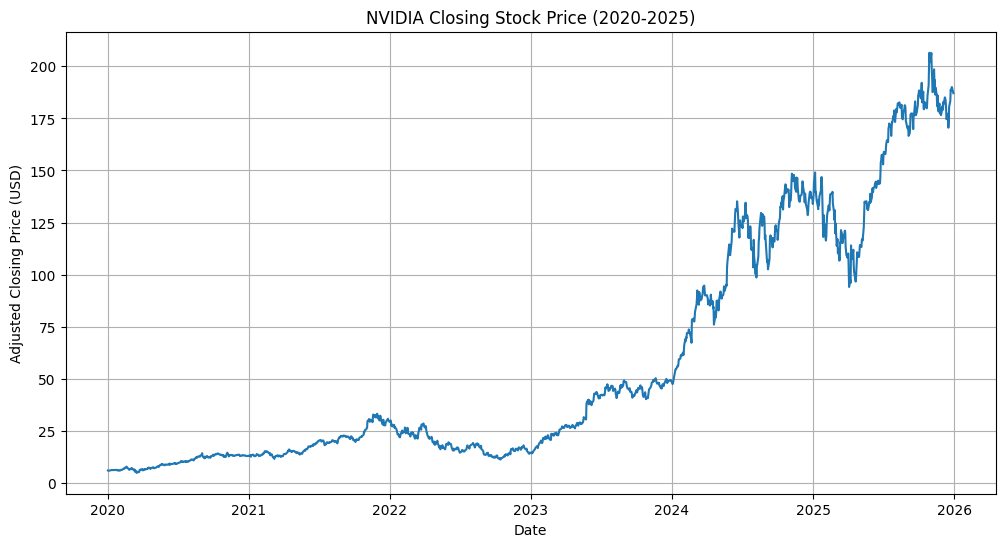

In [43]:
plt.figure(figsize=(12, 6))
plt.plot(nvidiadata["Close"])
plt.title("NVIDIA Closing Stock Price (2020-2025)")
plt.xlabel("Date")
plt.ylabel("Adjusted Closing Price (USD)")
plt.grid(True)
plt.show()